In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('placement.csv')

In [3]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [4]:
df = df.iloc[:, 1:]

In [6]:
df.shape

(100, 3)

In [5]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [7]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model 
# 5. Evaluate the mode / model selection
# 6. Deploy the model

In [9]:
import matplotlib.pyplot as plt

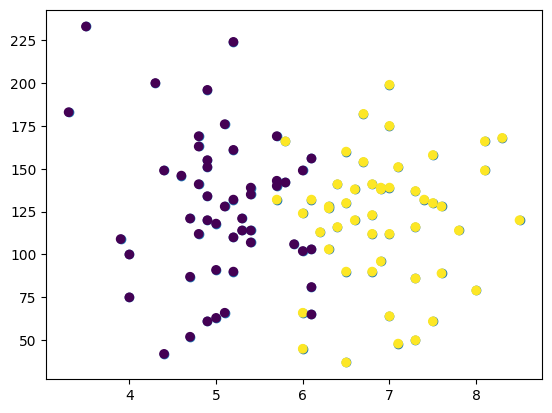

In [11]:
# this plots a scatter plot between cgpa and iq . But here we are not able to 
# figure out which dots got placement so we will add color parameter.
# plt.scatter(df['cgpa'],df['iq'])

plt.scatter(df['cgpa'], df['iq'], c = df['placement'])

#### Here we'll be using logistic regression algorithm

In [16]:
X = df.iloc[:, :2]
y = df.iloc[:,-1]

In [14]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [17]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.1)

In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
scaler = StandardScaler()

In [25]:
X_train = scaler.fit_transform(X_train)

In [26]:
X_train

array([[ 8.81510723e-03, -1.51137722e+00],
       [-1.22529990e+00,  5.73680450e-01],
       [-8.72695616e-01, -1.58956688e+00],
       [ 3.61419396e-01,  4.43364346e-01],
       [-6.08242399e-01, -7.79000712e-02],
       [ 1.33108119e+00,  1.56668916e-01],
       [-1.04899776e+00,  4.43364346e-01],
       [ 1.33108119e+00, -1.64169332e+00],
       [-1.04899776e+00, -3.12469059e-01],
       [-5.20091327e-01, -4.42785163e-01],
       [ 1.85117252e-01, -2.86405838e-01],
       [-5.20091327e-01,  2.86985021e-01],
       [-7.84544543e-01,  1.04542475e-01],
       [-9.60846688e-01,  8.08249437e-01],
       [ 8.90325830e-01,  3.91237904e-01],
       [-2.19496170e+00,  2.84118066e+00],
       [ 8.81510723e-03,  2.89591343e-04],
       [ 2.73268324e-01, -5.47038046e-01],
       [ 1.15477905e+00,  3.39111462e-01],
       [ 2.73268324e-01,  1.04542475e-01],
       [ 7.14023686e-01, -8.85859917e-01],
       [ 2.03628977e+00,  1.14707131e+00],
       [ 1.33108119e+00,  8.86439100e-01],
       [-1.

In [27]:
X_test = scaler.transform(X_test)

In [28]:
X_test

array([[-0.87269562, -0.15608973],
       [-1.04899776,  1.17313453],
       [ 1.41923226, -0.91192314],
       [ 0.09696618,  0.20879536],
       [ 0.00881511, -2.05870485],
       [-0.69639347, -0.88585992],
       [-1.40160205, -2.13689452],
       [-0.16748704,  1.09494487],
       [ 0.89032583,  1.95503115],
       [ 1.85998763,  0.65187011]])

In [29]:
from sklearn.linear_model import LogisticRegression

In [30]:
clf = LogisticRegression()

In [31]:
# Model training
clf.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [36]:
y_pred = clf.predict(X_test)

In [33]:
y_test

67    0
75    0
42    1
71    1
10    1
28    0
96    0
85    1
26    1
37    1
Name: placement, dtype: int64

In [34]:
from sklearn.metrics import accuracy_score

In [37]:
# Accuracy of the model
accuracy_score(y_test, y_pred)

0.9

In [40]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

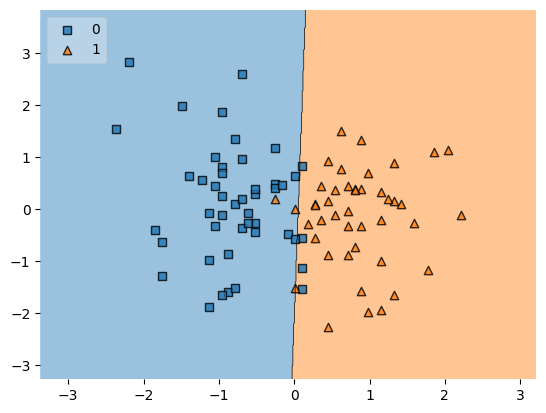

In [43]:
# it requires numpy array as input and since we have used StandardScaler
# it is a numpy array now X_train and y_train
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)


In [44]:
# everything in python is an object. But what pickle do is , it converts 
# the object into file and we can use this file in any other environment
import pickle

In [45]:
pickle.dump(clf, open('model.pkl', 'wb'))